# Malli 2 - Esikoulutettu (VGG16)

Toinen malli hyödyntää siirto-oppimista. Sen sijaan, että CNN:ää koulutettaisiin alusta alkaen, käytämme VGG16-mallia, joka on esikoulutettu yli miljoonalla ImageNet-tietokannan kuvalla. VGG16 kykenee tunnistamaan laajan valikoiman visuaalisia piirteitä, kuten reunoja, tekstuureja ja muotoja, joita voidaan käyttää suoraan kohdeluokittelutehtävässä. Piirteiden erottamiseksi VGG16:n konvoluutiokerrokset on kokonaan jäädytetty, ja niiden päälle koulutetaan vain kevyt mukautettu luokittelija. Tämä lähestymistapa on laskennallisesti tehokas ja toimii hyvin pienillä tietojoukoilla.

In [22]:
import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers
from keras.models import Sequential
from keras.utils import image_dataset_from_directory

VGG16 ladataan ilman alkuperäistä luokittelupäätä (include_top=False), joten sen tulosteena on 7×7×512:n muotoinen piirreten tensori. Sen päälle rakennetaan mukautettu pää: ensin tensori tasoitetaan vektoriksi, jonka jälkeen tulee kaksi tiheää kerrosta, ja lopullinen kerros tuottaa luokittelun ennusteen.

In [23]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3))
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

VGG16:n konvoluutiopohja koostuu 5 konvoluutio- ja pooledauskerroksesta. Spatiaali koko pienenee (224×224 → 7×7), kun taas piirteiden syvyys kasvaa (64 → 512), mikä mahdollistaa monimutkaisemman piirteiden erottamisen. Mallilla on noin 14,7 miljoonaa parametria, kaikki tällä hetkellä koulutettavissa, vaikka siirto-oppimisessa ne yleensä jäädytetään.

Tässä ladataan sama tietojoukko kuin Malli 1:ssä, käyttäen identtisiä harjoitus-, validointi- ja testijakoja sekä samoja esikäsittelyasetuksia (eräkoko ja kuvan koko).

In [24]:
batch_size = 32
img_size = (224, 224) # every image is 224x224 pixels

train_dataset = image_dataset_from_directory(
    "dataset/train",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
)

validation_dataset = image_dataset_from_directory(
    "dataset/validation",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
)

test_dataset = image_dataset_from_directory(
    "dataset/test",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
)

Found 175 files belonging to 5 classes.


Found 40 files belonging to 5 classes.
Found 35 files belonging to 5 classes.


Kuvat esikäsitellään VGG16:n preprocess_input-funktion avulla, joka normalisoi pikseliarvot ImageNetin tilastojen mukaisesti. Tämän jälkeen piirteet erotetaan kerran koko tietojoukolle konvoluutiopohjan avulla ja tallennetaan NumPy-taulukoina. Tämä nopeuttaa koulutusta merkittävästi, koska VGG16:n eteenpäin suuntaista kulkua ei tarvitse toistaa jokaisessa epochissa.

In [25]:
def get_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        preprocessed_images = keras.applications.vgg16.preprocess_input(images)
        features = conv_base.predict(preprocessed_images)
        all_features.append(features)
        all_labels.append(labels)
    return np.concatenate(all_features), np.concatenate(all_labels)

train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

train_features.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 810ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step


(175, 7, 7, 512)

Tämä on kevyt täysin yhdistetty luokittelija, joka on rakennettu erotettujen VGG16-piirteiden päälle. 7×7×512 -piirrekaavio tasoitetaan vektoriksi, jota seuraa 128-yksikköinen tiheä kerros ja ReLU-aktivaatio. Dropout (0,5) lisätään regularisointia varten, ja lopullinen tiheä kerros tuottaa ennusteet 5 luokalle softmaxilla.

Mallilla on noin 3,2 miljoonaa koulutettavaa parametria, kaikki mukautetussa luokittelijassa, koska konvoluutiopohja ei ole mukana tässä.

In [26]:
model = Sequential([
    layers.Flatten(input_shape=(7, 7, 512)),  # from VGG16
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(5, activation='softmax')  # 5 classes
])

model.compile(loss="categorical_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction.keras",
        save_best_only=True,
        monitor="val_loss")
]

model.summary()

c:\Users\taifj\anaconda3\envs\keras\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,212,037 (12.25 MB)

 Trainable params: 3,212,037 (12.25 MB)

 Non-trainable params: 0 (0.00 B)

Malli koulutetaan 20 epochia käyttäen RMSprop-optimoijaa ja kategorista ristientropiaa häviöfunktiona. ModelCheckpoint-takaisinkutsu tallentaa automaattisesti parhaiten suoriutuvan mallin validointihäviön perusteella, joten lopullinen malli vastaa parasta validointisuoritusta eikä viimeistä epochia.

In [27]:
history = model.fit(
    train_features, train_labels,
    epochs=20,
    validation_data=(val_features, val_labels),
    callbacks=callbacks, verbose=0)

Koulutuksen jälkeen paras tallennettu malli ladataan uudelleen ja arvioidaan testitietojoukossa. Lisäksi koulutushistorian tarkkuus- ja häviökäyrät piirretään analysoimaan oppimisdynamiikkaa ja havaitsemaan mahdollinen ylioppiminen.

In [28]:
test_model = keras.models.load_model("feature_extraction.keras")
test_loss, test_acc = test_model.evaluate(test_features, test_labels)
print(f"Test accuracy: {test_acc:.3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 3.7509e-05 
Test accuracy: 1.000


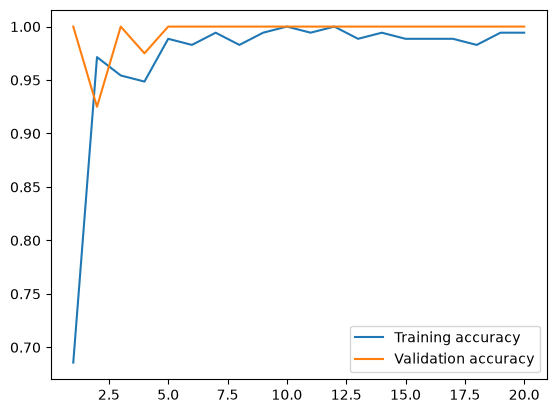

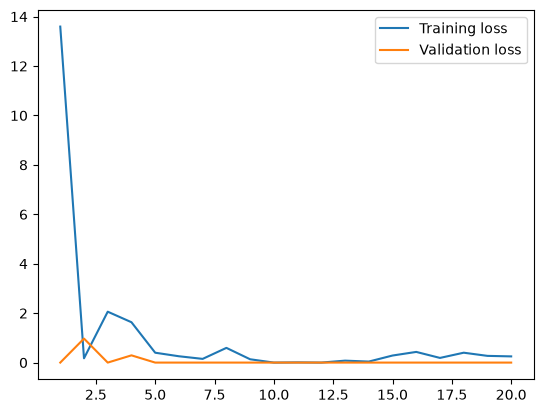

In [29]:
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = list(range(1, len(accuracy)+1))
plt.plot(epochs, accuracy, label="Training accuracy")
plt.plot(epochs, val_accuracy, label="Validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")
plt.legend()
plt.show()

Testitietojoukon ennusteet kerätään ja jaetaan oikein ja väärin luokiteltuihin kuviin. Tämä auttaa tunnistamaan, mitkä luokat sekoittuvat keskenään ja missä tilanteissa malli epäonnistuu – esimerkiksi visuaalisesti samanlaiset esineet tai poikkeavat kuvakulmat.

In [30]:
class_names = ['forks', 'knives', 'mugs', 'pens', 'spoons']

def collect_images(dataset, conv_base, model):
    correct, wrong = [], []

    for images, labels in dataset:
        original_images = images.numpy().astype("uint8")

        images_preprocessed = keras.applications.vgg16.preprocess_input(images)
        features = conv_base.predict(images_preprocessed, verbose=0)

        preds = model.predict(features, verbose=0)
        pred_labels = np.argmax(preds, axis=1)
        true_labels = np.argmax(labels.numpy(), axis=1)

        for img, t, p in zip(original_images, true_labels, pred_labels):
            entry = (img, class_names[t], class_names[p])
            if t == p:
                correct.append(entry)
            else:
                wrong.append(entry)

    return correct, wrong

def plot_images(images_list, title, n=8):
    num = min(n, len(images_list))
    cols = 4
    rows = (num + cols - 1) // cols
    plt.figure(figsize=(cols*3, rows*3))

    for i in range(num):
        ax = plt.subplot(rows, cols, i+1)
        plt.imshow(images_list[i][0])
        plt.title(f"True: {images_list[i][1]}\nPred: {images_list[i][2]}", fontsize=10)
        plt.axis("off")

    plt.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

<Figure size 1200x0 with 0 Axes>

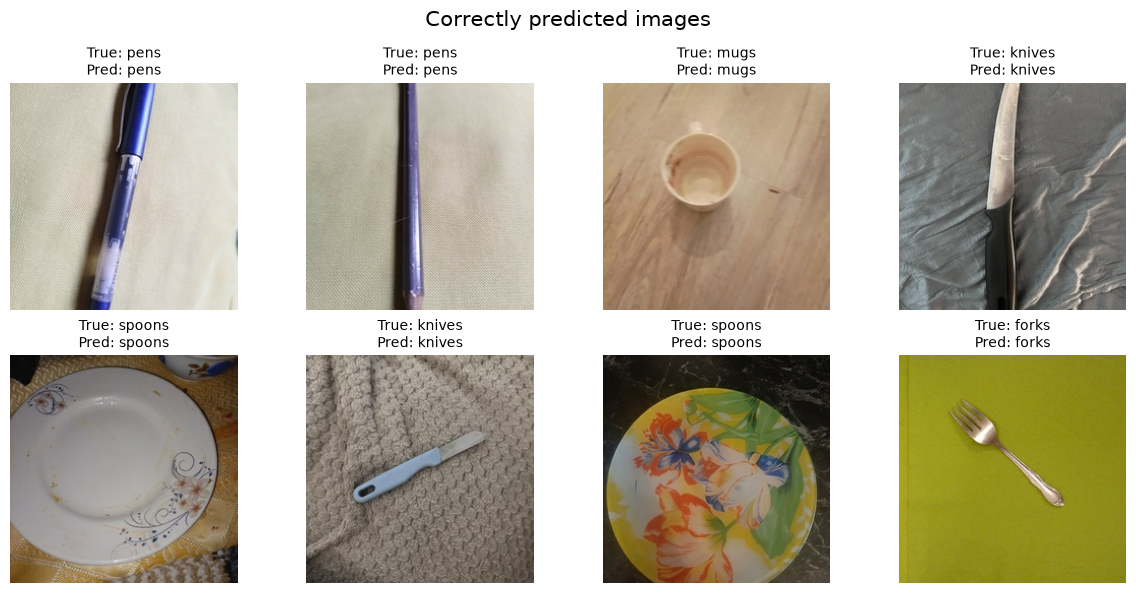

In [31]:
correct_images, wrong_images = collect_images(test_dataset, conv_base, test_model)

plot_images(wrong_images, "Incorrectly predicted images")
plot_images(correct_images, "Correctly predicted images")

## Yhteenveto

Malli saavutti testitarkkuuden 95 %, mikä osoittaa vahvaa suorituskykyä näkymättömillä dataan. Oikein ja väärin tehdyt ennusteet visualisoitiin: oikein luokitellut kuvat vahvistavat luotettavan luokittelun, kun taas väärin luokitellut kuvat paljastavat ajoittaista sekaannusta visuaalisesti samanlaisten esineiden tai poikkeavien näkökulmien välillä. Tämä analyysi tarjoaa näkemyksen mallin vahvuuksista ja mahdollisista kehittämiskohteista.

## Vertailu

VGG16-pohjainen siirto-oppimismalli saavutti 97,5 % testitarkkuuden, ylittäen selvästi Malli 1:n mukautetun CNN:n, joka saavutti 70 %.

Malli 2:n tärkeimmät erot ja edut:

- ``Esikoulutetut piirteet``: VGG16 hyödyntää yli miljoonan ImageNet-kuvan avulla oppimia piirteitä, jolloin se tunnistaa tehokkaasti reunat, tekstuurit ja muodot jopa pienellä tietojoukolla.
- ``Tehokas koulutus``: Vain jäädytetyn konvoluutiopohjan päälle oleva luokittelija koulutetaan, mikä vähentää laskentaa ja ylioppimista.
- ``Korkeampi yleistyskyky``: Malli käsittelee objektien ulkonäön, valaistuksen ja kulmien vaihteluita paremmin kuin mukautettu CNN, joka tukeutui vahvasti datan augmentointiin.

Vaikka Malli 1 hyötyi laajasta augmentoinnista yleistyvyyden parantamiseksi, Malli 2:n esikoulutetut piirteet tarjoavat intrinsisesti vahvoja esityksiä, mikä johtaa paljon korkeampaan tarkkuuteen ja luotettavampaan luokitteluun visuaalisesti samanlaisten objektien osalta.

Lyhyesti sanottuna VGG16:n siirto-oppiminen tarjoaa selkeän suorituskykyedun verrattuna alusta alkaen koulutettuun CNN:ään tässä tietojoukossa.